### 다중 분류 실습 문제

## Intel Image Dataset
: 자연 풍경 및 도시 환경 사진을 6개 클래스로 분류하는 이미지 데이터셋, 클러스터링

- 학습데이터 : 약 14,000
- 테스트 데이터 : 약 3,000
- 예측용 데이터 : 약 7,000
- 이미지 크기 : 150 x 150(컬러 이미지)
- 입력 이미지 : RGB 이미지 (64× 64로 크기 변경)
- 입력 특징 수: 3 × 64 × 64 = 12,288
- 출력 클래스: 6개

| 클래스 이름 | 의미 |
|:---:|:---|
| `buildings` | 건물 |
| `forest` | 숲 |
| `glacier` | 빙하 |
| `mountain` | 산 |
| `sea` | 바다 |
| `street` | 거리 |

#### STEP 1. 데이터 불러오기 및 전처리

**실습 조건**
- `torchvision.datasets.ImageFolder`를 이용해 학습 데이터와 테스트 데이터를 불러온다.
- 이미지를 `(64, 64)` 크기로 통일한다.
- `transforms.ToTensor()`를 이용해 Tensor로 변환한다.
- RGB 이미지이므로 이미지 한 장의 형태는 `[3, 64, 64]`이다.
- `ImageFolder`가 부여한 클래스 인덱스와 클래스 이름을 확인한다.
- 학습 데이터와 테스트 데이터의 클래스 순서가 같은지 확인한다.
- 데이터 개수와 첫 번째 이미지의 shape을 출력한다.

In [1]:
# 데이터를 다운로드 하려면 설치 필요
%pip install kagglehub

Note: you may need to restart the kernel to use updated packages.


In [2]:
# function 파일 오류 수정 후 런타임을 재시작하지 않고 수정내용을 반영하는 방법
import importlib
import multiclass_functions
importlib.reload(multiclass_functions)

from multiclass_functions import *

In [3]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms, datasets
# datasets:  이미지 파일과 정답 레이블을 관리하고, 모델 학습에 사용할 수 있는 Dataset 객체를 생성하는 모듈
# transforms: 모델이 학습할 수 있도록 이미지의 크기, 자료형, 차원, 픽셀값 등을 변환하는 모듈입니다. 데이터 증강(Data Augmentation)에도 사용됩니다.
import matplotlib.pyplot as plt
import numpy as np
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [4]:
# 이미지 다운로드
import kagglehub
import shutil

# 저장 위치
data_dir = os.path.join(os.getcwd(), "data")

# 1. KaggleHub에서 데이터셋 가져오기
dataset_path = kagglehub.dataset_download(
    "puneet6060/intel-image-classification"
)

print("Kaggle 데이터 위치:", dataset_path)

# 2. data에 복사
os.makedirs(data_dir, exist_ok=True)

shutil.copytree(
    dataset_path,
    data_dir,
    dirs_exist_ok=True
)

print("저장 완료!")
print("최종 저장 위치:", data_dir)

c:\Users\mega\KYJ\PyTorch\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Kaggle 데이터 위치: C:\Users\mega\.cache\kagglehub\datasets\puneet6060\intel-image-classification\versions\2
저장 완료!
최종 저장 위치: c:\Users\mega\KYJ\PyTorch\06.Dropout\data


ImageFolder()는 모든 이미지를 메모리에 올려놓는 것이 아니라, 이미지 파일의 경로와 레이블을 관리하다가 필요한 시점에 이미지를 불러옵니다. 이를 **Lazy Loading(지연 로딩)**이라고 합니다.<br>

In [5]:
# Colab의 지연 로딩 문제 

# import os
import time
# import kagglehub
# import shutil

# 저장 위치
data_dir = os.path.join(os.getcwd(), "data")

# 1. 다운로드 시간 측정
start = time.perf_counter()

dataset_path = kagglehub.dataset_download(
    "puneet6060/intel-image-classification"
)

download_time = time.perf_counter() - start

# 2. 복사 시간 측정
start = time.perf_counter()

os.makedirs(data_dir, exist_ok=True)

shutil.copytree(
    dataset_path,
    data_dir,
    dirs_exist_ok=True
)

copy_time = time.perf_counter() - start

# 3. 결과 출력
print(f"다운로드 소요시간: {download_time:.2f}초")
print(f"파일 복사 소요시간: {copy_time:.2f}초")
print(f"전체 소요시간: {download_time + copy_time:.2f}초")

다운로드 소요시간: 0.71초
파일 복사 소요시간: 16.31초
전체 소요시간: 17.02초


In [28]:
# 이미지 전처리 및 Totensor() 설정
transform = transforms.Compose([
    transforms.Resize((64,64)),
    transforms.AutoAugment(transforms.AutoAugmentPolicy.IMAGENET),
    transforms.ToTensor()
])

train_DS = datasets.ImageFolder(root='data/seg_train/seg_train', transform=transform)
test_DS = datasets.ImageFolder(root='data/seg_test/seg_test', transform=transform)

#### STEP 2. DataLoader 생성 및 데이터 확인

**실습 조건**
- 학습률(LR): `1e-3`
- Epoch: 10 이상
- Batch size: 32
- Optimizer: Adam
- Loss function: CrossEntropyLoss
- 학습 데이터는 `shuffle=True`, 테스트 데이터는 `shuffle=False`로 설정한다.
- 첫 번째 배치의 `x_batch`, `y_batch` shape을 확인한다.
- 이미지를 시각화하고 이미지의 클래스 이름을 표시한다.

In [51]:
BATCH_SIZE = 32
LR = 1e-2
EPOCH = 15
criterion = nn.CrossEntropyLoss()
new_model_train = True

model_type = 'CNN_drop'
dataset = 'CIFAR10'

save_dir = 'results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'

In [30]:
train_DL = DataLoader(train_DS, batch_size= BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size= BATCH_SIZE, shuffle=True)

In [31]:
print(train_DS)
print(test_DS)
print(test_DS.classes)
print(test_DS.class_to_idx)

Dataset ImageFolder
    Number of datapoints: 14034
    Root location: data/seg_train/seg_train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               AutoAugment(policy=AutoAugmentPolicy.IMAGENET, fill=None)
               ToTensor()
           )
Dataset ImageFolder
    Number of datapoints: 3000
    Root location: data/seg_test/seg_test
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               AutoAugment(policy=AutoAugmentPolicy.IMAGENET, fill=None)
               ToTensor()
           )
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
{'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


torch.Size([32, 3, 64, 64])
forest


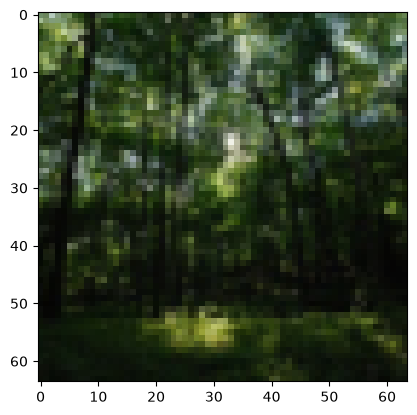

In [32]:
x_batch, y_batch = next(iter(train_DL))
print(x_batch.shape)

plt.imshow(x_batch[0].permute(1,2,0))
# 파이토치의 (channel, height, width)의 구조를 matplotlib.pyplot.imshow에서는 읽지 못함
# (height, width, channel)로 구조를 바꾸어주어야 읽을 수 있음
print(test_DS.classes[y_batch[0]])

#### STEP 3. MLP 모델 만들기

**모델 조건**

- 입력 이미지 크기: `[3, 64, 64]`
- `torch.flatten(x, start_dim=1)`을 이용해 배치 차원은 유지하고 나머지 차원을 펼친다.
- 입력 특징 수: `3 × 64 × 64`<br><br>

- 3가지의 모델 정의하기
    1. 은닉층 노드 수: 30개
    2. 은닉층 노드 수: 100개
    3. 여러개의 은닉층 

In [52]:
class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(
        nn.Linear(3*64*64, 30),
        nn.BatchNorm1d(30),  
        nn.ReLU(),
        nn.Linear(30, 6)
    )

  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

# Dropout
class MLP_drop(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(
        nn.Linear(3*64*64, 512),  
        nn.BatchNorm1d(512),  
        nn.ReLU(),
        nn.Dropout(p=.3),
        nn.Linear(512, 256),  
        nn.BatchNorm1d(256),
        nn.ReLU(),
        nn.Dropout(p=.3),          
        nn.Linear(256, 6)
    )
  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

# 은닉층 뉴런의 개수를 늘림: 30 -> 100
class MLP_shallow(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(
        nn.Linear(3*64*64, 512),  
        nn.BatchNorm1d(512),  
        nn.ReLU(),
        nn.Linear(512, 256), 
        nn.BatchNorm1d(256),  
        nn.ReLU(),
        nn.Linear(256, 6)
    )
  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

# 은닉층의 층수를 늘림: 4 -> 34
class MLP_deep(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(
        nn.Linear(3*64*64, 30),
        nn.BatchNorm1d(30),
        nn.ReLU(),
        *[i for _ in range(10) for i in [nn.Linear(30, 30),
                                         nn.BatchNorm1d(30), 
                                         nn.ReLU()]],
        nn.Linear(30, 6)
    )

  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

class CNN_drop(nn.Module):
    def __init__(self,*args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv1 = nn.Sequential(nn.Conv2d(3,32,3,padding=1),
                                   nn.BatchNorm2d(32),
                                   nn.ReLU(),
                                   nn.Dropout(p=.3)
                                   )
        self.maxpool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(nn.Conv2d(32,64,3,padding=1),
                                   nn.BatchNorm2d(64),
                                   nn.ReLU(),
                                   nn.Dropout(p=.3)
                                   )
        self.maxpool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Sequential(nn.Conv2d(64,128,3,padding=1),
                                   nn.BatchNorm2d(128),
                                   nn.ReLU(),
                                   nn.Dropout(p=.3)
                                   )
        self.maxpool3 = nn.MaxPool2d(2)
        self.adaptpool = nn.AdaptiveAvgPool2d((1,1))
        self.fc = nn.Linear(128,6)

    def forward(self, x, *args, **kwargs):
        x = self.conv1(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = self.conv3(x)
        x = self.maxpool3(x)
        x = self.adaptpool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

In [53]:
model = globals()[model_type]().to(device)
print(model)
# model_type 은 하이퍼 파라미터 셀에서 model_type = 'MLP' 로 정의했기 때문에 변경희망시
# model_type = 'MLP_shallow' 로 변경하여 다시 셀 2 개를 실행하면 됨

x_batch, _ = next(iter(train_DL))
print(x_batch.shape)
print(model(x_batch.to(device)).shape)

CNN_drop(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
  )
  (maxpool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
  )
  (maxpool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
  )
  (maxpool3): MaxPool2d(kernel_size=2, s

#### STEP 4. 모델 학습시키고 저장하기

Epoch : 1, train loss : 1.290
--------------------
Epoch : 2, train loss : 1.044
--------------------
Epoch : 3, train loss : 0.933
--------------------
Epoch : 4, train loss : 0.871
--------------------
Epoch : 5, train loss : 0.828
--------------------
Epoch : 6, train loss : 0.794
--------------------
Epoch : 7, train loss : 0.768
--------------------
Epoch : 8, train loss : 0.741
--------------------
Epoch : 9, train loss : 0.707
--------------------
Epoch : 10, train loss : 0.699
--------------------
Epoch : 11, train loss : 0.690
--------------------
Epoch : 12, train loss : 0.675
--------------------
Epoch : 13, train loss : 0.654
--------------------
Epoch : 14, train loss : 0.645
--------------------
Epoch : 15, train loss : 0.636
--------------------


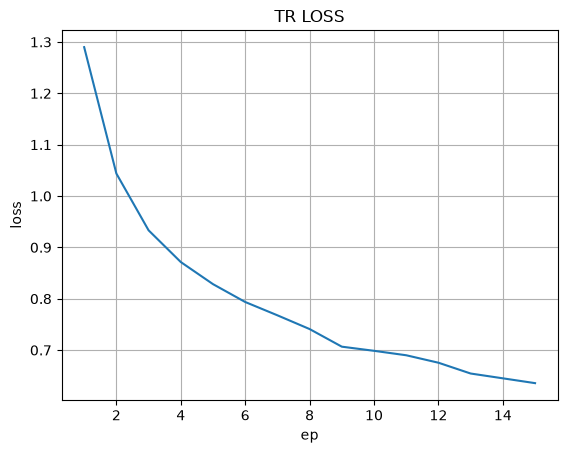

In [54]:
# if new_model_train == True:
if new_model_train:
  optimizer = optim.Adam(model.parameters(), lr=LR)
  loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

  torch.save(model, save_model_path)

  plt.figure()
  plt.plot(range(1, EPOCH+1), loss_history)
  plt.xlabel('ep')
  plt.ylabel('loss')
  plt.title('TR LOSS')
  plt.grid()

In [46]:
load_model = torch.load(save_model_path, map_location= device, weights_only=False)

#### STEP 5. 테스트 및 그래프

In [ ]:
Accuracy(load_model, train_DL, 'Train')
Accuracy(load_model, test_DL, 'Test')
print(count_params(load_model))   

# MLP_shallow
# Train Accuracy : 8676 / 14034 (61.8 %), Test Accuracy : 1596 / 3000 (53.2 %), parameters: 6426374

# MLP_drop
# Train Accuracy : 10986 / 14034 (78.3 %), Test Accuracy : 1922 / 3000 (64.1 %), parameters: 6427402

# MLP_drop + AutoAugment(ImageNet)
# Train Accuracy : 7602 / 14034 (54.2 %), Test Accuracy : 1446 / 3000 (48.2 %), parameters: 6427402

# CNN_drop


Train Accuracy : 8676 / 14034 (61.8 %)
Test Accuracy : 1596 / 3000 (53.2 %)
6426374


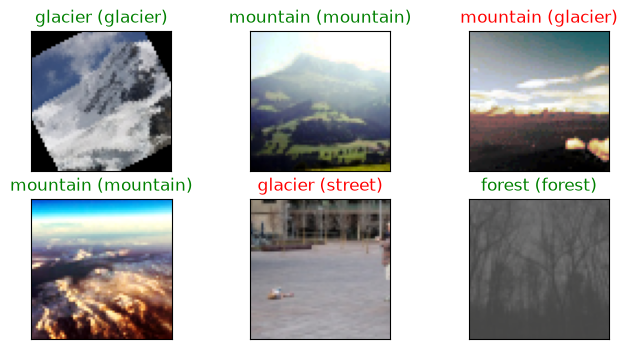

In [49]:
Test_plot(load_model, test_DL)

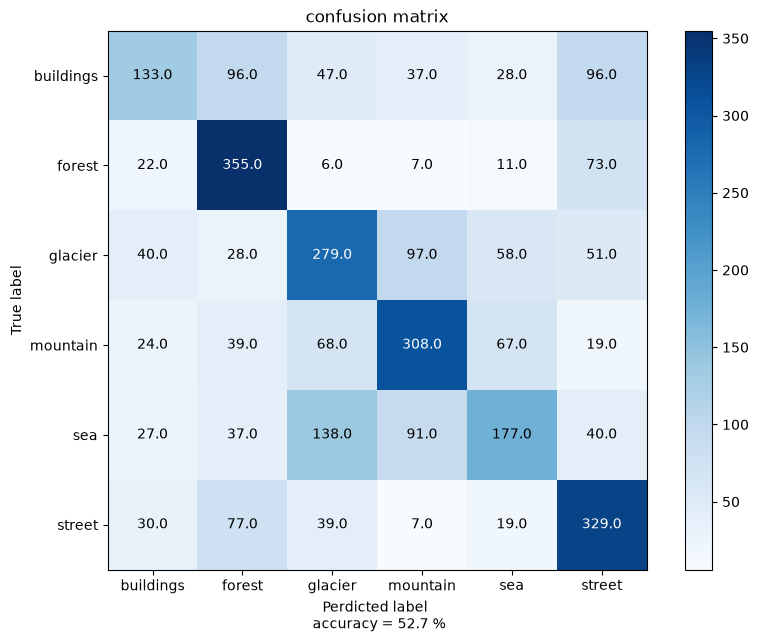

In [50]:
confusion = get_conf(load_model, test_DL)

plot_confusion_matrix(confusion, test_DS.classes)

#### STEP 7. 모델 파라미터 개수 확인

In [41]:
print(count_params(load_model))

6427402
